In [11]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
import pandas as pd

df = pd.read_csv(r"D:\ethans\Ethans\Airline1.csv")

In [4]:
Destination_Value = df['Destination'].mode()[0]
df['Destination'] = df['Destination'].fillna(Destination_Value)
df['Destination']

0        New Delhi
1         Banglore
2           Cochin
3         Banglore
4        New Delhi
           ...    
10683     Banglore
10684     Banglore
10685        Delhi
10686    New Delhi
10687       Cochin
Name: Destination, Length: 10688, dtype: str

In [5]:
Route_Value = df['Route'].mode()[0]
df['Route'] = df['Route'].fillna(Route_Value)
df['Route']

0                    BLR _ DEL
1        CCU _ IXR _ BBI _ BLR
2        DEL _ LKO _ BOM _ COK
3              CCU _ NAG _ BLR
4              BLR _ NAG _ DEL
                 ...          
10683                CCU ? BLR
10684                CCU ? BLR
10685                BLR ? DEL
10686                BLR ? DEL
10687    DEL ? GOI ? BOM ? COK
Name: Route, Length: 10688, dtype: str

In [6]:
Total_Stops_Value = df['Total_Stops'].mode()[0]
df['Total_Stops'] = df['Total_Stops'].fillna(Total_Stops_Value)
df['Total_Stops']

0        non-stop
1         2 stops
2         2 stops
3          1 stop
4          1 stop
           ...   
10683    non-stop
10684    non-stop
10685    non-stop
10686    non-stop
10687     2 stops
Name: Total_Stops, Length: 10688, dtype: str

In [7]:
Price_Value = df['Price'].mean()
df['Price'] = df['Price'].fillna(Price_Value)
df['Price']

0         3897.0
1         7662.0
2        13882.0
3         6218.0
4        13302.0
          ...   
10683     4107.0
10684     4145.0
10685     7229.0
10686    12648.0
10687    11753.0
Name: Price, Length: 10688, dtype: float64

In [9]:
sorted = df.groupby('Airline')['Price'].count().sort_values().index
sns.countplot(x = df['Airline'], order = sorted)
plt.xticks(rotation = 90)

NameError: name 'sns' is not defined

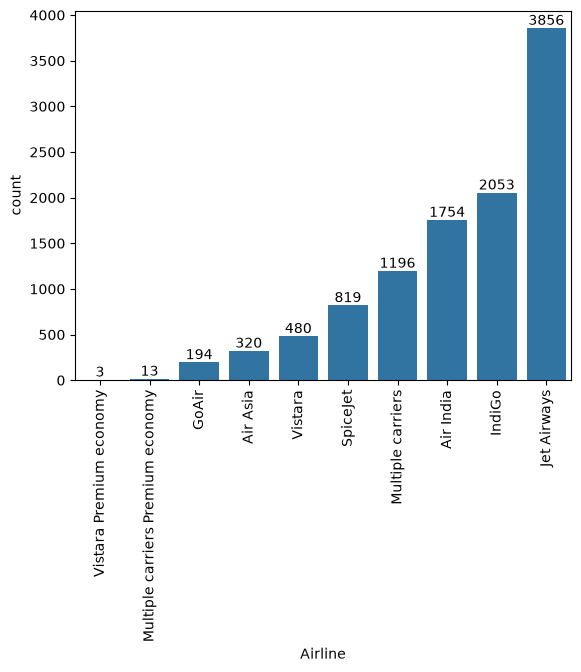

In [12]:
sorted = df.groupby('Airline')['Price'].count().sort_values().index
ax = sns.countplot(x = df['Airline'], order = sorted)
ax.bar_label(ax.containers[0])
plt.xticks(rotation = 90)
plt.show()

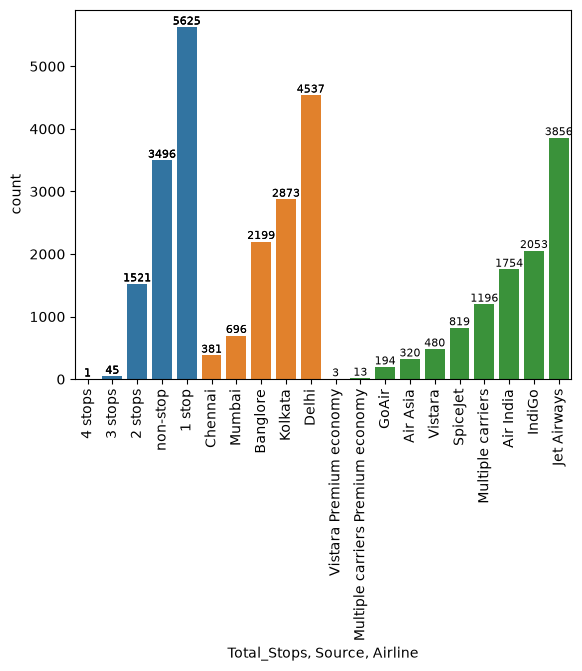

In [14]:
columns = ['Total_Stops', 'Source', 'Airline']

for key,value in enumerate(columns):
    order = df[value].value_counts().sort_values().index
    ax=sns.countplot(data=df, x=value, order=order)
    plt.xlabel("Total_Stops, Source, Airline")
    # ax.bar_label(ax.containers[0])
    for i in ax.containers:
        ax.bar_label(i, fmt='%.0f', size=8)
    plt.xticks(rotation = 90)
plt.show()

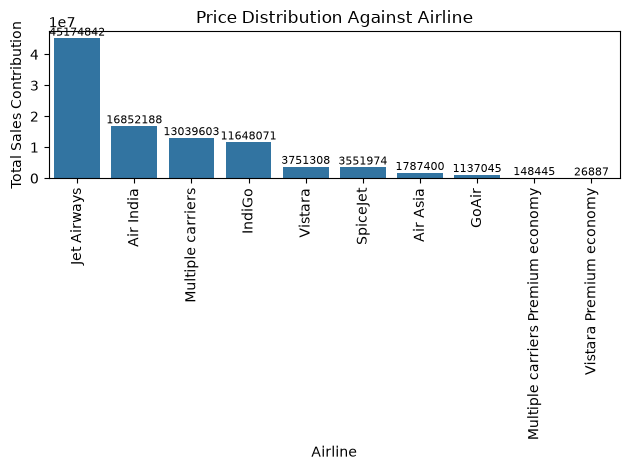

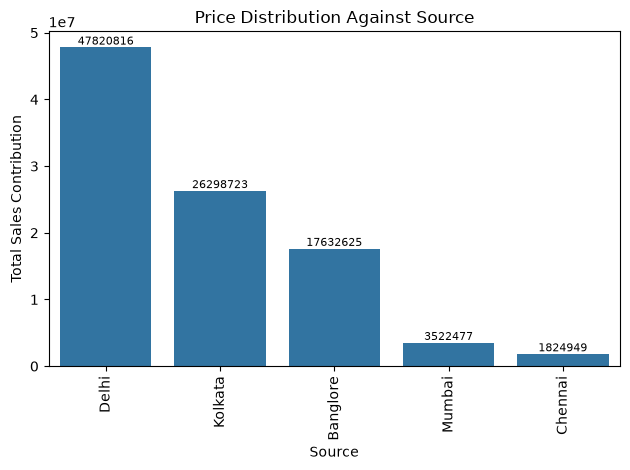

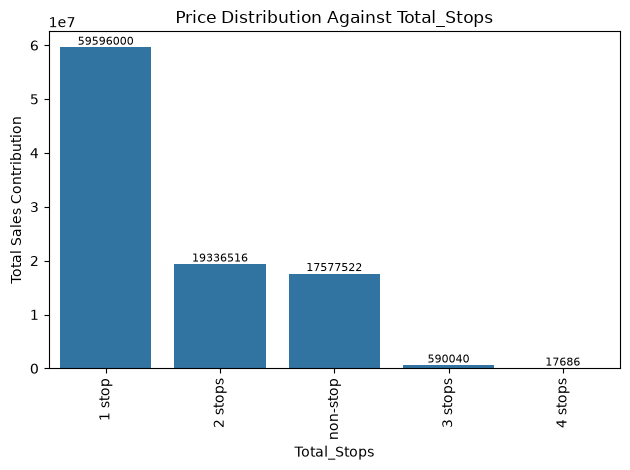

In [16]:
columns = ['Airline', 'Source', 'Total_Stops']

for value in columns:

    order = df.groupby(value)['Price'].sum().sort_values(ascending=False).index

    ax = sns.barplot(
        data=df,
        x=value,
        y='Price',
        order=order,
        estimator='sum',
        errorbar=None
    )

    ax.bar_label(ax.containers[0], fmt='%.0f', size=8)

    plt.xlabel(value)
    plt.ylabel("Total Sales Contribution")
    plt.title("Price Distribution Against " + value)

    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

In [17]:
columns = ['mean', 'sum', 'count', 'min', 'max']

for value in columns:

    newDF = df.groupby('Airline')['Price'].agg(value).sort_values(ascending=False)

    print("Airline Price", value.upper())
    print(newDF)
    print("--------------------------------")

Airline Price MEAN
Airline
Jet Airways                          11715.467324
Multiple carriers Premium economy    11418.846154
Multiple carriers                    10902.678094
Air India                             9607.861023
Vistara Premium economy               8962.333333
Vistara                               7815.224202
GoAir                                 5861.056701
IndiGo                                5673.682903
Air Asia                              5585.625000
SpiceJet                              4336.964591
Name: Price, dtype: float64
--------------------------------
Airline Price SUM
Airline
Jet Airways                          4.517484e+07
Air India                            1.685219e+07
Multiple carriers                    1.303960e+07
IndiGo                               1.164807e+07
Vistara                              3.751308e+06
SpiceJet                             3.551974e+06
Air Asia                             1.787400e+06
GoAir                               

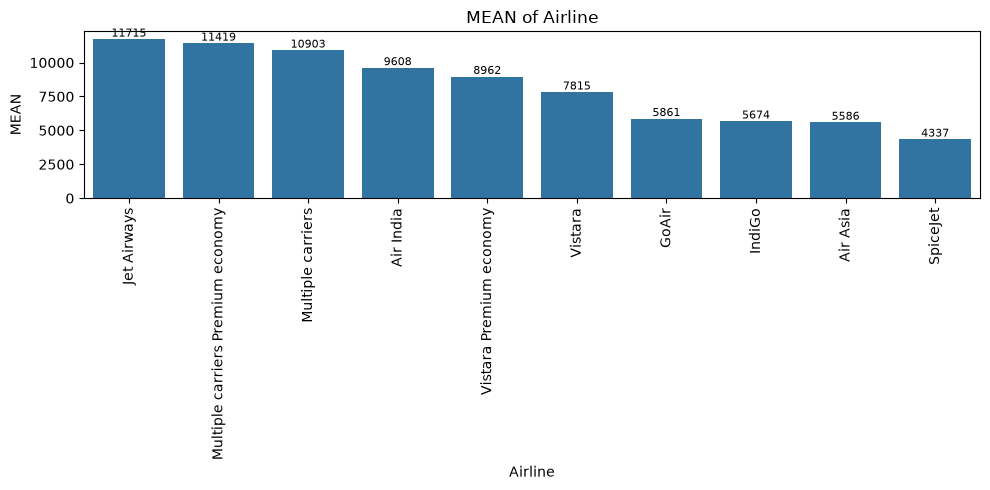

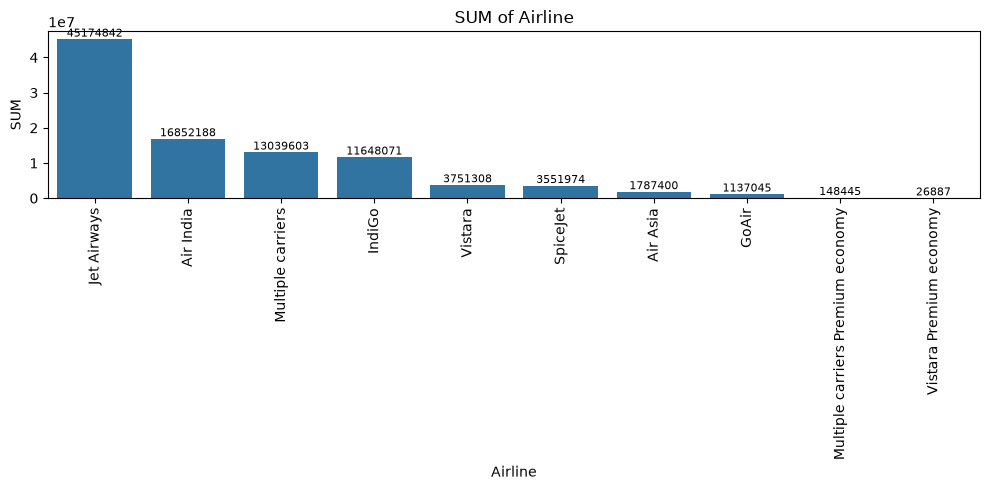

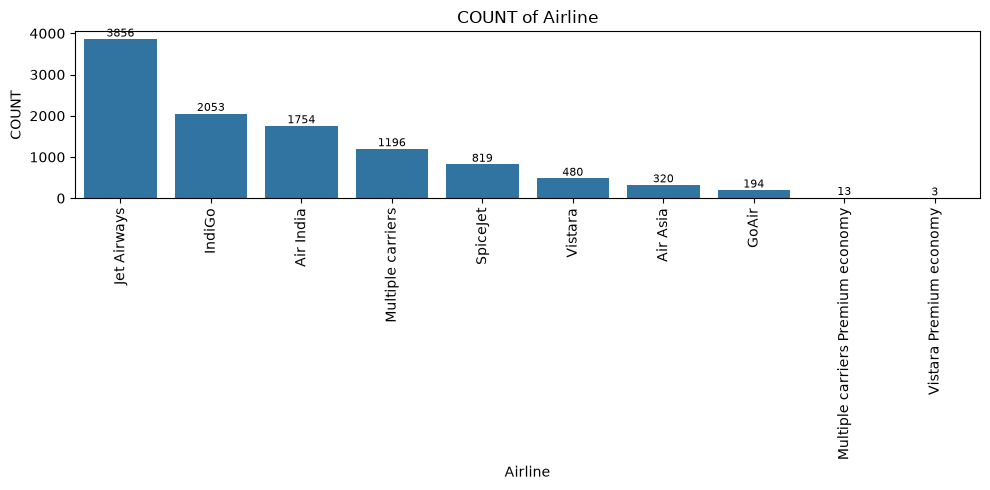

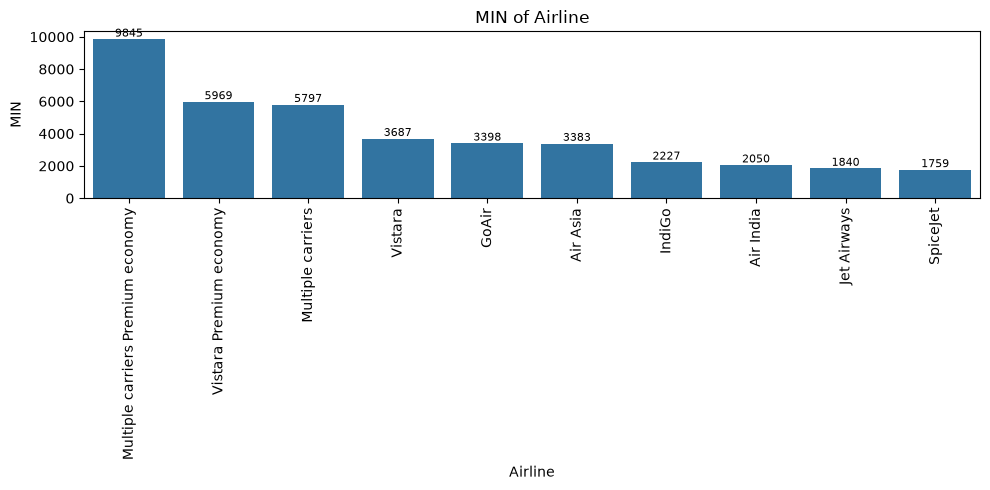

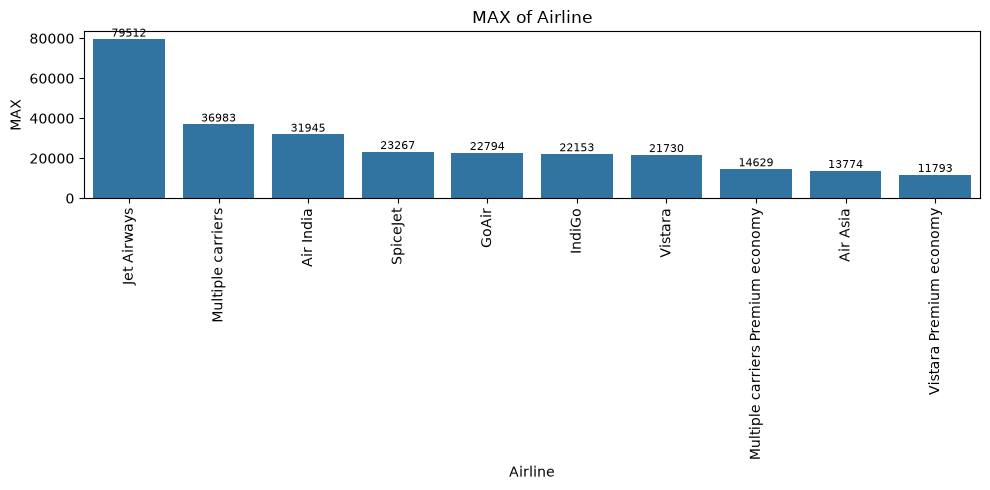

In [18]:
columns = ['mean', 'sum', 'count', 'min', 'max']

for value in columns:

    newDF = df.groupby('Airline')['Price'].agg(value).sort_values(ascending=False)

    plt.figure(figsize=(10,5))

    ax = sns.barplot(
        x=newDF.index,
        y=newDF.values,
        errorbar=None
    )

    ax.bar_label(ax.containers[0], fmt='%.0f', size=8)

    plt.xlabel("Airline")
    plt.ylabel(value.upper())
    plt.title(value.upper() + " of Airline")

    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

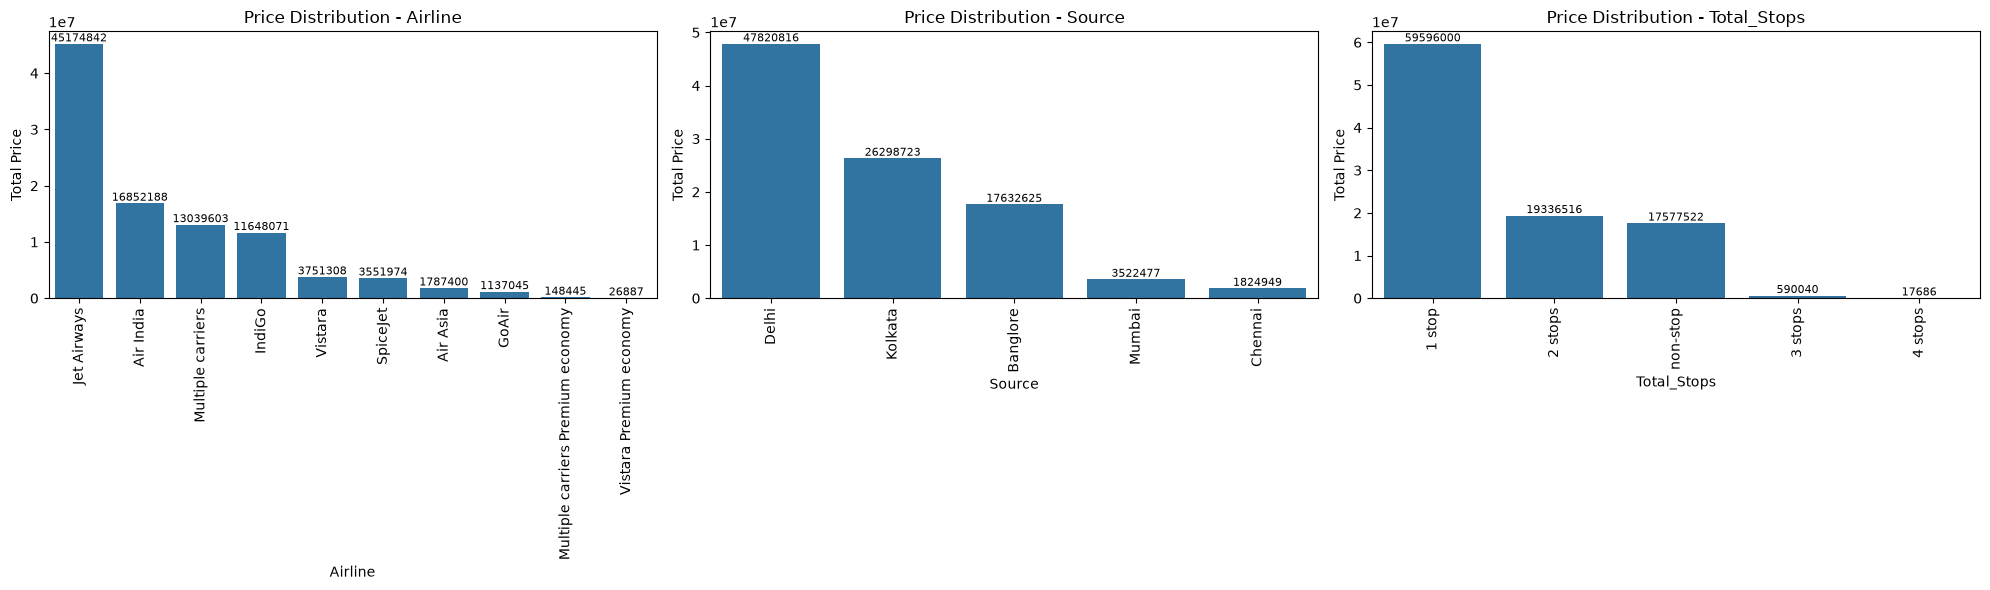

In [19]:
columns = ['Airline', 'Source', 'Total_Stops']

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for i, value in enumerate(columns):

    newDF = df.groupby(value)['Price'].sum().sort_values(ascending=False)

    ax = sns.barplot(
        x=newDF.index,
        y=newDF.values,
        ax=axes[i],
        errorbar=None
    )

    ax.bar_label(ax.containers[0], fmt='%.0f', size=8)

    ax.set_title("Price Distribution - " + value)
    ax.set_xlabel(value)
    ax.set_ylabel("Total Price")
    ax.tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

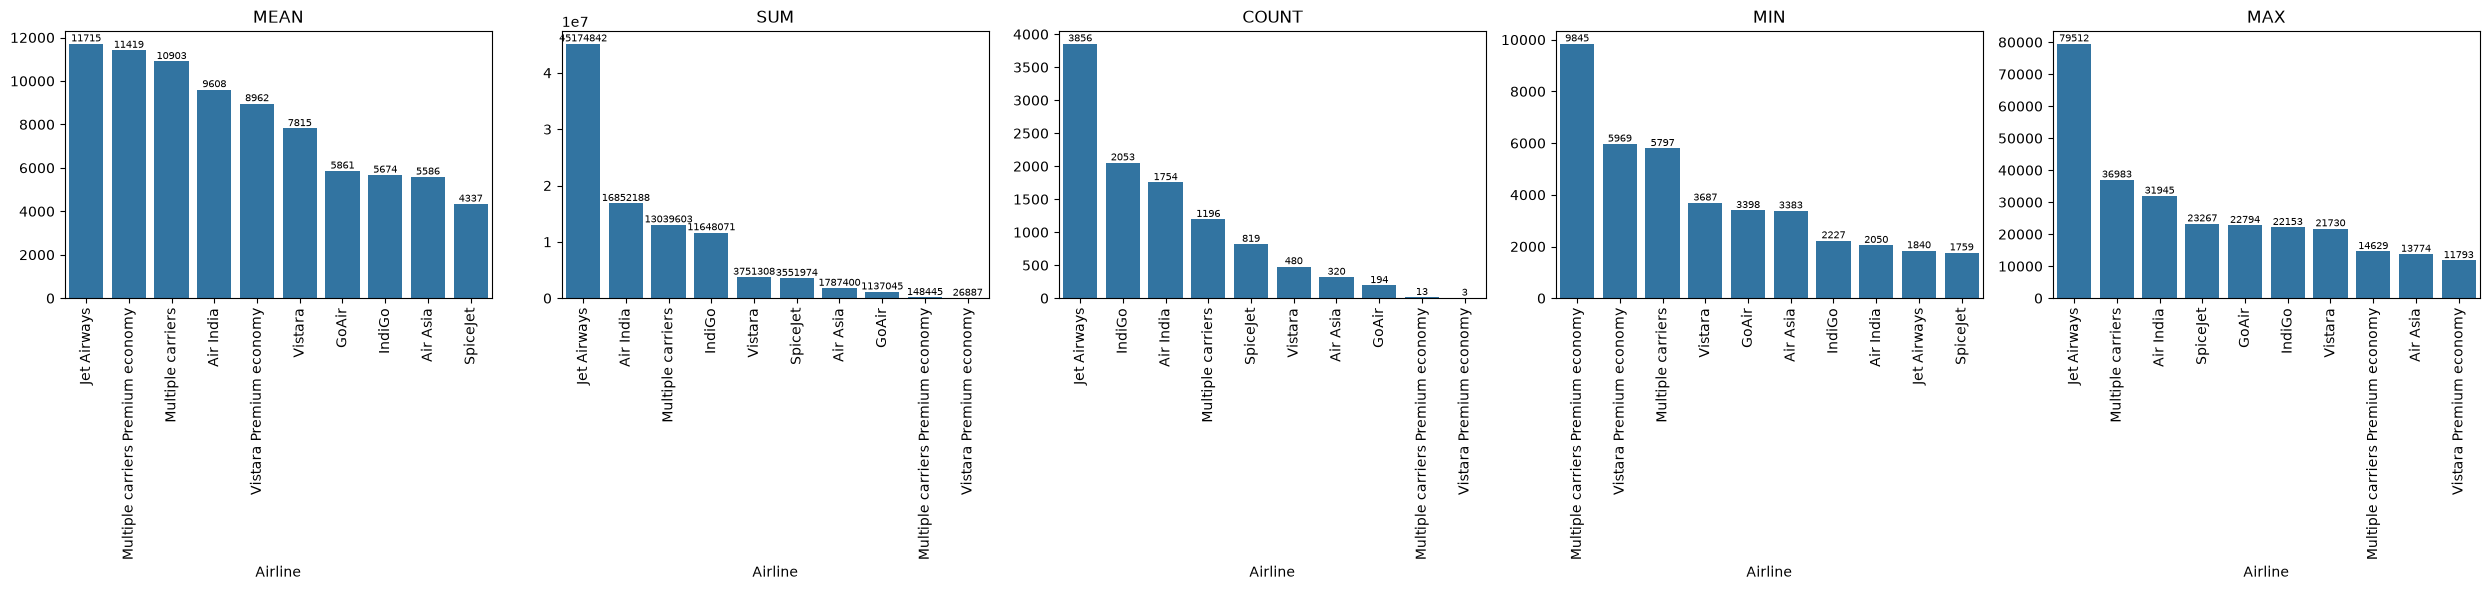

In [20]:
columns = ['mean', 'sum', 'count', 'min', 'max']

fig, axes = plt.subplots(1, 5, figsize=(25, 6))

for i, value in enumerate(columns):

    newDF = df.groupby('Airline')['Price'].agg(value).sort_values(ascending=False)

    ax = sns.barplot(
        x=newDF.index,
        y=newDF.values,
        ax=axes[i],
        errorbar=None
    )

    ax.bar_label(ax.containers[0], fmt='%.0f', size=7)

    ax.set_title(value.upper())
    ax.set_xlabel("Airline")
    ax.tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

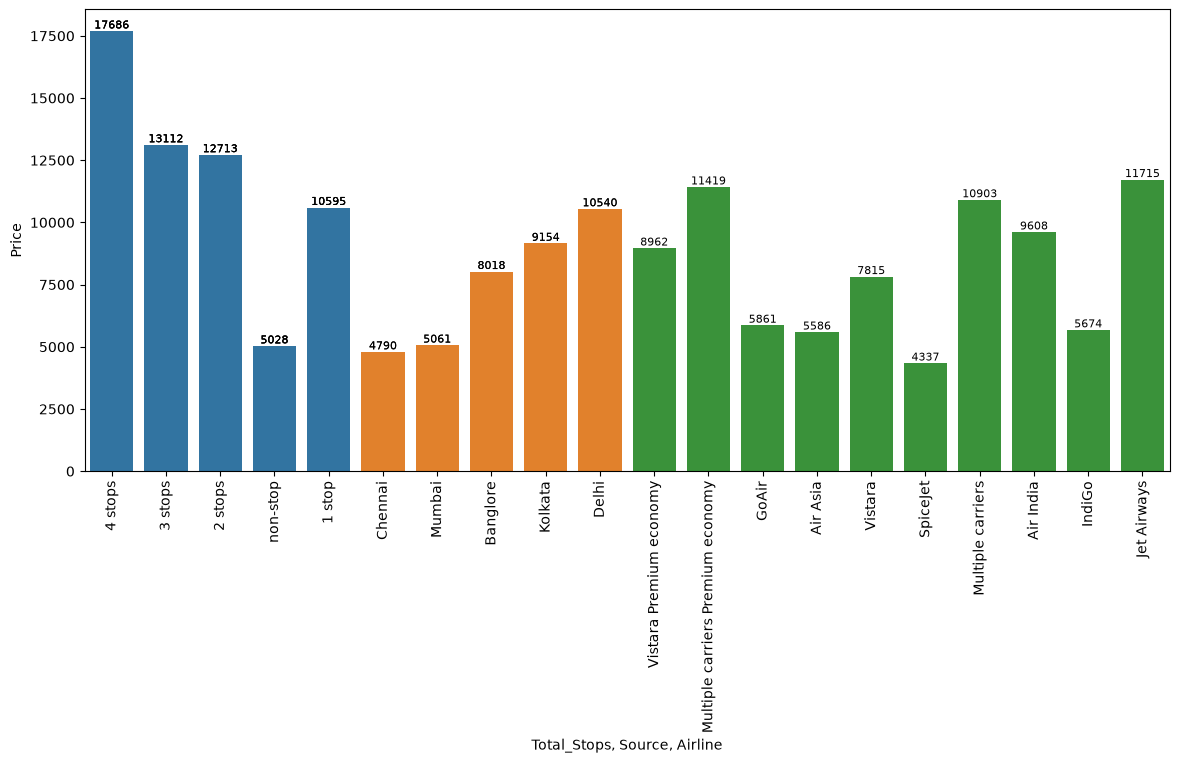

In [21]:
columns = ['Total_Stops', 'Source', 'Airline']
plt.figure(figsize=(14,6))

for value in columns:
    order = df.groupby(value)['Price'].count().sort_values().index
    ax=sns.barplot(data=df, x=value, y='Price', order=order, errorbar=None)
    plt.xlabel("Total_Stops, Source, Airline")
    for i in ax.containers:
        ax.bar_label(i, fmt='%.0f', size=8)
    plt.xticks(rotation = 90)
plt.show()

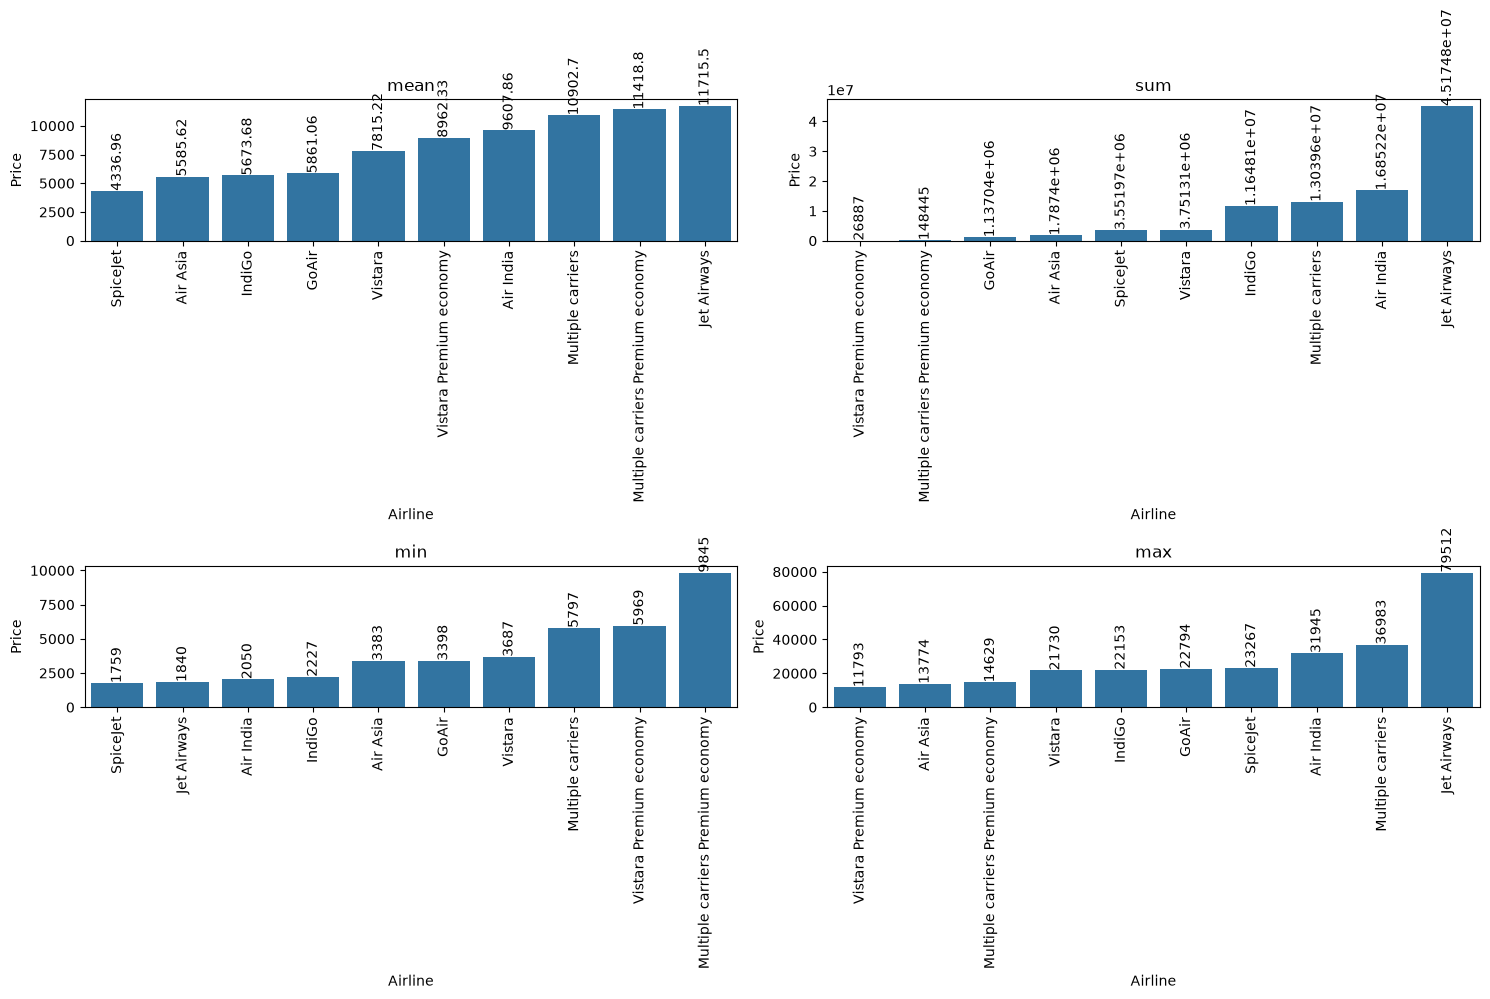

In [27]:
aggList = ["mean","sum","min","max"]
plt.figure(figsize=(15,10))
for key,value in enumerate(aggList):
    newDF = df.groupby('Airline')['Price'].agg(value).sort_values()
    newDF = pd.DataFrame(newDF.reset_index())
    plt.subplot(2,2,key+1)

    ax=sns.barplot(data=newDF,x='Airline',y='Price')

    ax.bar_label(ax.containers[0],rotation=90)
    plt.xticks(rotation=90)
    plt.title(value)
plt.tight_layout()
plt.show()

#total stops
#source

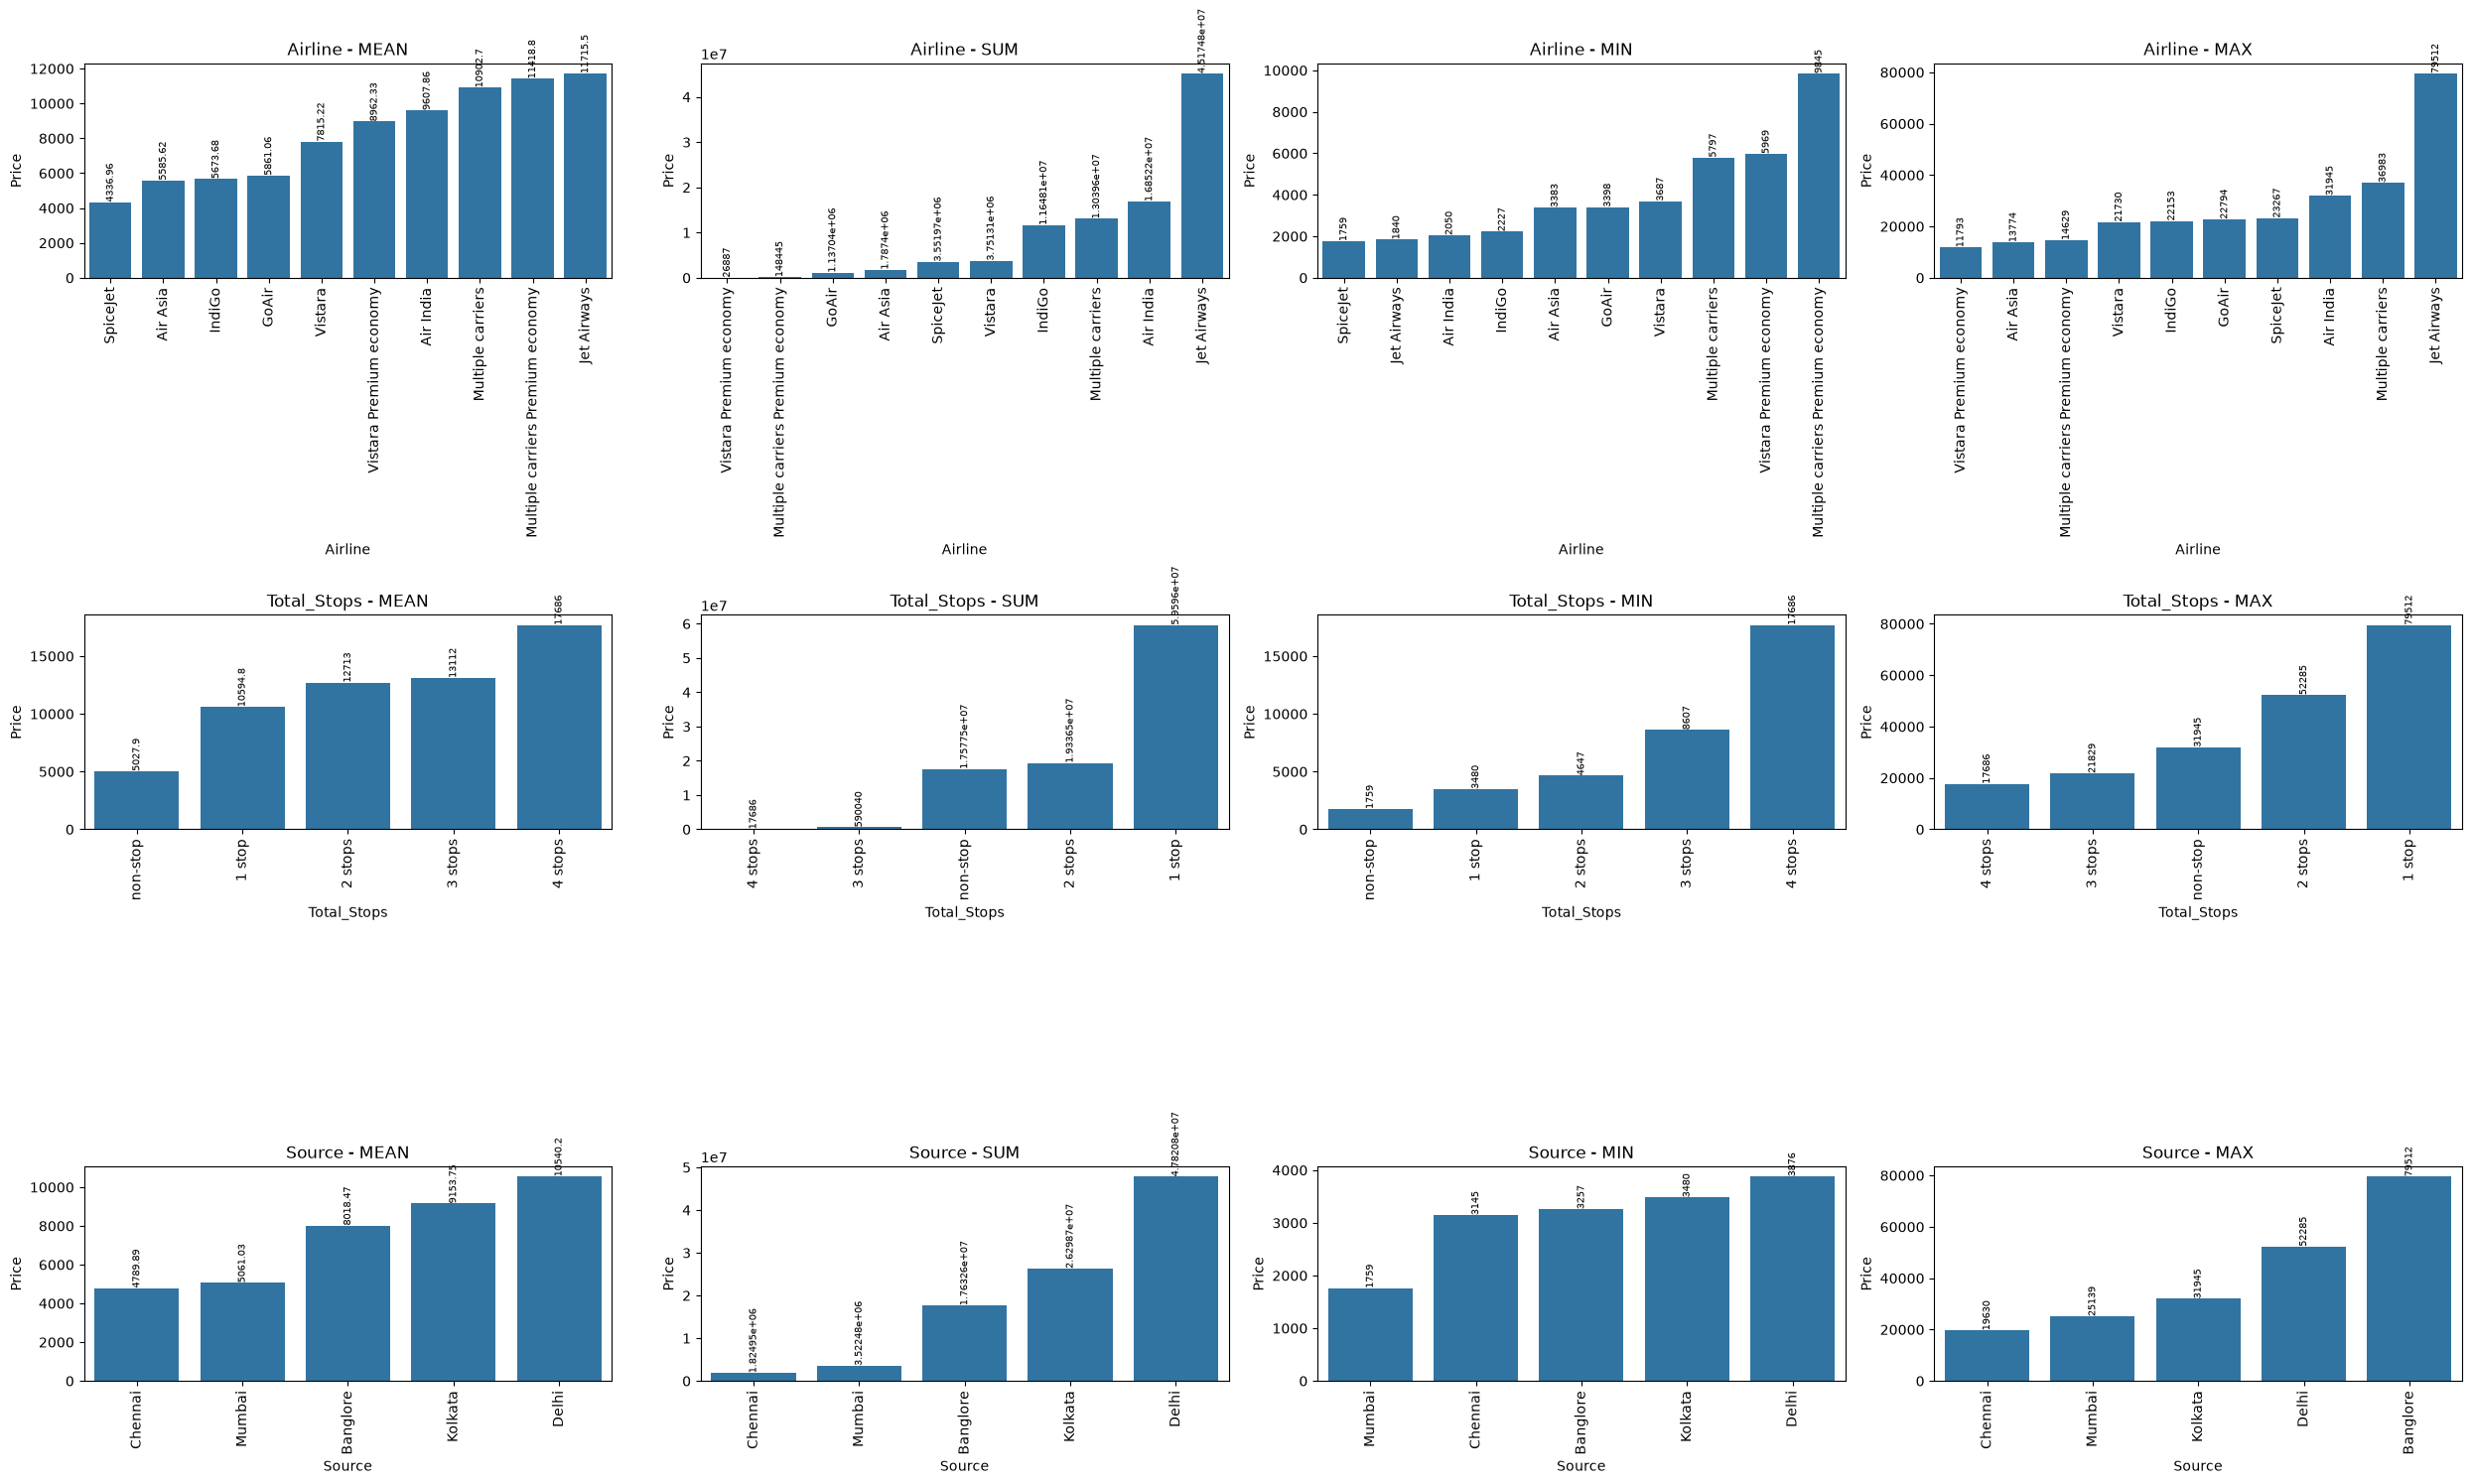

In [28]:
aggList = ["mean", "sum", "min", "max"]

columns = ['Airline', 'Total_Stops', 'Source']

plt.figure(figsize=(25, 15))

for col_index, col in enumerate(columns):

    for key, value in enumerate(aggList):

        newDF = df.groupby(col)['Price'].agg(value).sort_values()

        newDF = pd.DataFrame(newDF.reset_index())

        plt.subplot(3, 4, col_index * 4 + key + 1)

        ax = sns.barplot(data=newDF, x=col, y='Price')

        ax.bar_label(ax.containers[0], rotation=90, size=7)

        plt.xticks(rotation=90)
        plt.title(col + " - " + value.upper())
        plt.xlabel(col)
        plt.ylabel("Price")

plt.tight_layout()
plt.show()

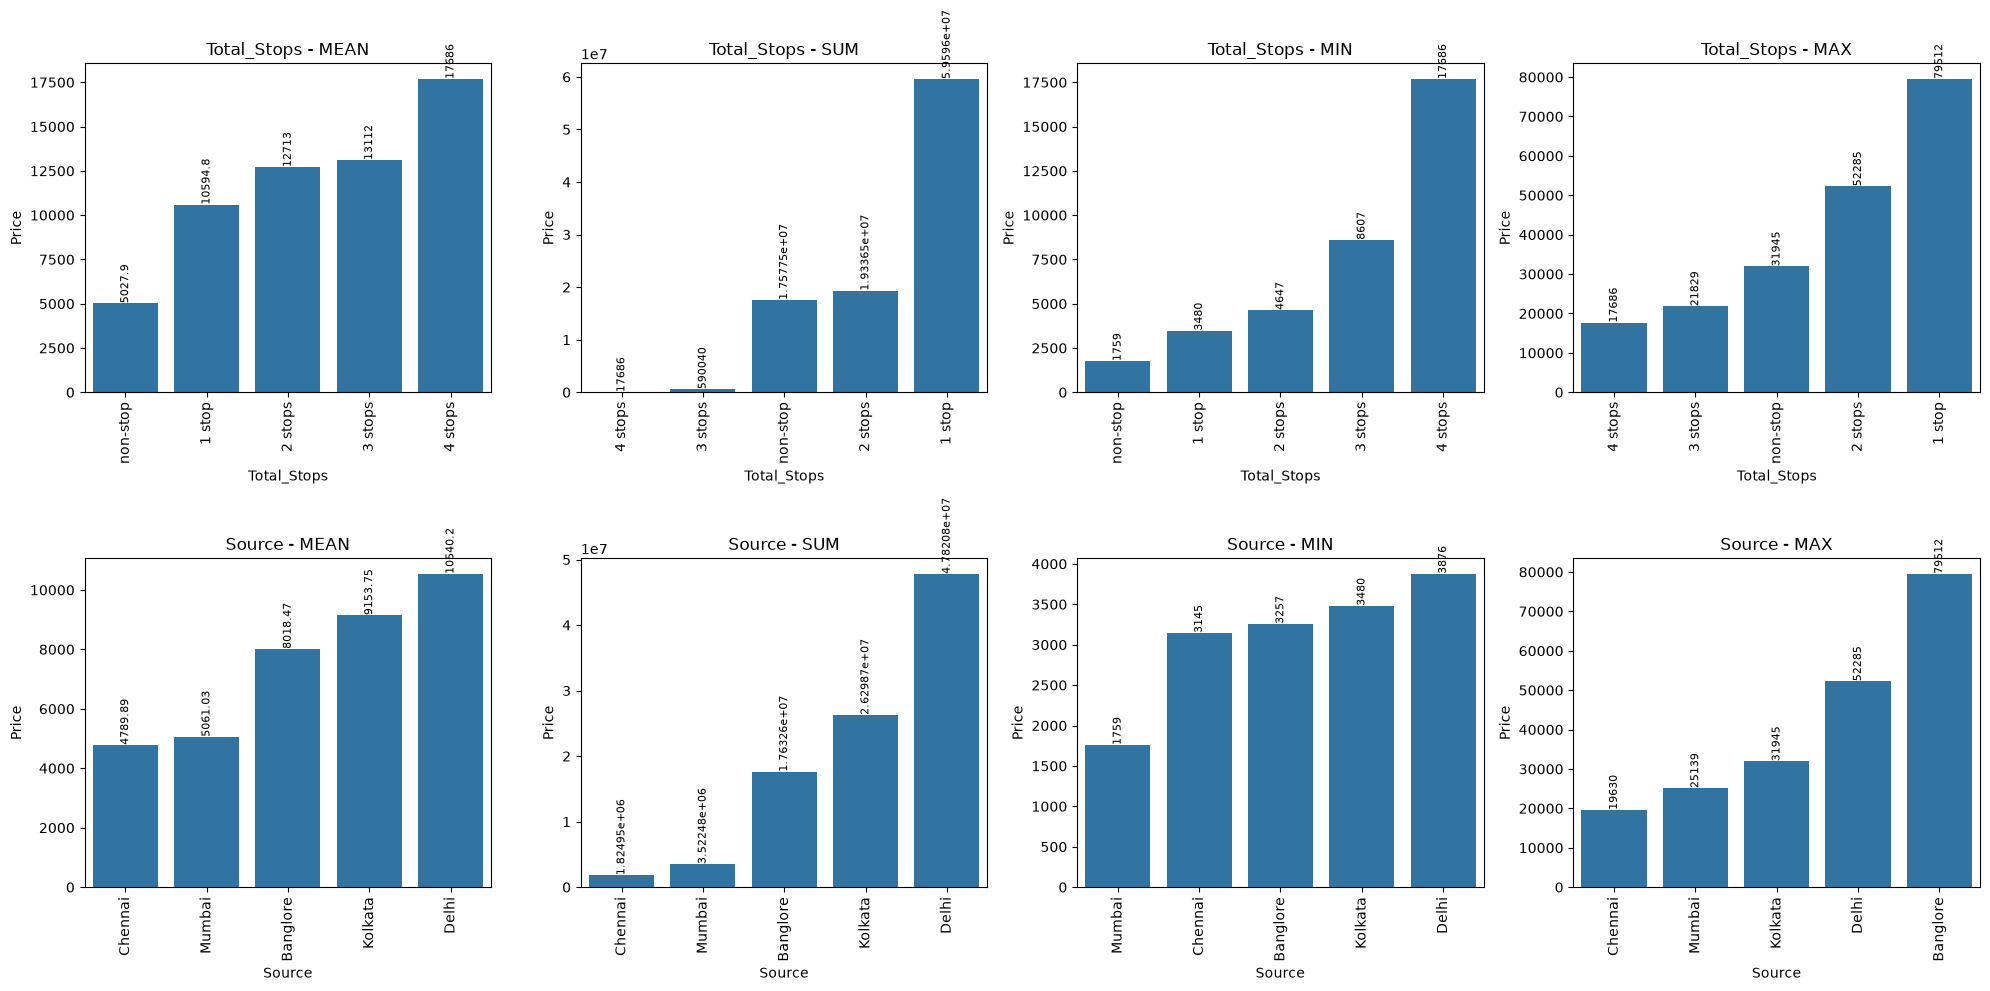

In [29]:
aggList = ["mean", "sum", "min", "max"]

columns = ['Total_Stops', 'Source']

plt.figure(figsize=(20, 10))

for col_index, col in enumerate(columns):

    for key, value in enumerate(aggList):

        newDF = df.groupby(col)['Price'].agg(value).sort_values()

        newDF = pd.DataFrame(newDF.reset_index())

        plt.subplot(2, 4, col_index * 4 + key + 1)

        ax = sns.barplot(data=newDF, x=col, y='Price')

        ax.bar_label(ax.containers[0], rotation=90, size=8)

        plt.xticks(rotation=90)
        plt.title(col + " - " + value.upper())

plt.tight_layout()
plt.show()

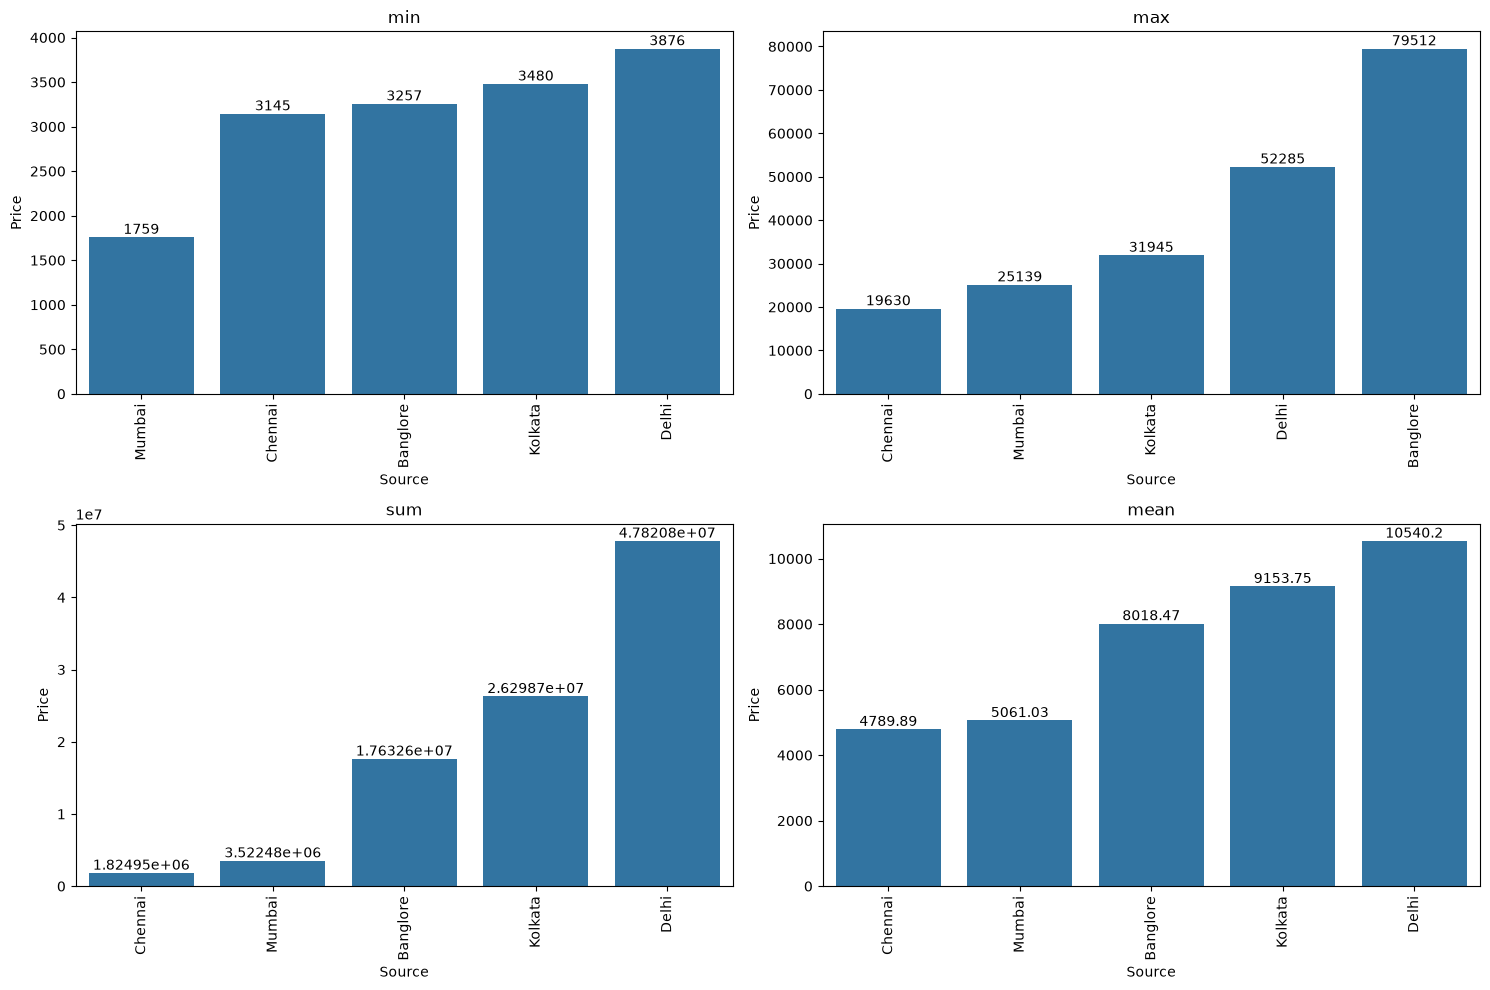

In [30]:
aggList = ["min", "max", "sum", "mean"]

plt.figure(figsize=(15,10))
for key,value in enumerate(aggList):
    newdf = df.groupby('Source')['Price'].agg(value).sort_values()
    newdf = pd.DataFrame(newdf.reset_index())
    plt.subplot(2,2,key+1)

    ax = sns.barplot(data=newdf, x='Source', y='Price')
    ax.bar_label(ax.containers[0], size=10)
    plt.xticks(rotation=90)
    plt.title(value)
plt.tight_layout()
plt.show()